# In-Class Assignment: Multiple Regression
# Day 14
# CMSE 202

### <p style="text-align: right;"> &#9989; Dhruti Bhat</p>
#### <p style="text-align: right;"> &#9989; Ethan, Daniel, Brook</p>

---
### Goals

By the end of today's class, you'll have practiced:
* Loading and manipulating fixed-width column data
* Replacing/removing missing data entries
* Performing multiple regression using all features and a reduced set of statistically significant features.

### How this connects to the course learning goals

Beyond today's specific goals, this assignment builds toward several **course-level learning goals** (see the syllabus or the Day 1 notebook for the full CLG 1-7 list):

- **CLG 5 - Manipulate, analyze, and visualize datasets:** you'll wrangle real, messy UNESCO data (fixed-width parsing and handling missing values via imputation), fit multiple-regression models, and visualize the fits and residuals.
- **CLG 2 - Identify and use pre-existing tools:** you'll lean on `pandas` for data handling, `statsmodels` for regression, and `seaborn` for a correlation heatmap, reading their documentation for the right methods.
- **CLG 1 - Design and write programs to solve problems:** you'll build and compare full vs. reduced regression models to explain infant mortality.
- **CLG 7 - Communicate and explain your work in writing:** you'll interpret adjusted R^2, p-values, and residual plots, and justify your modeling decisions.
- **CLG 6 - Work in diverse groups:** you'll make several modeling decisions (how to handle bad data, which features to keep) together as a group.

### Agenda for today's class:

1. [Working with more unfamiliar data](#data)
1. [Multiple Regression](#multiple-regression)
1. [Visualization - How well does our model fit our data?](#viz)
1. [Wrapping up: multicollinearity & a look ahead to classification](#part4)

### Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
sns.set_context("notebook")
import pandas as pd
import statsmodels.api as sm


---
<a id="data"></a>
## 1. Working with more unfamiliar data 

We are going to work with some data generated by U.N.E.S.C.O. (United Nations Education, Scientific, and Cultural Organization) and data they collected relating to poverty and inequality in the world. There are two files you need to do the work:

- `poverty.dat` which is the data file itself
- `poverty.txt` which describes the data columns as **fixed width column** data. That is, this file describes the columns of the data for each category. For example, the data in columns 1-6 of `poverty.dat` contain the "live birth rates per 1,000 population".

You can download the files from here:

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/poverty.dat`

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/poverty.txt`

### How does one deal with a "fixed width column" data file?

Conveniently there is a fixed width column pandas data reader. Look it up and read in the data. **Check with your group members to make sure everyone can find the right function to use!**

Again we find ourselves with a data file that doesn't contain any column headers (argh!).  Take a look at the `poverty.txt` file for column information and give the columns in your Pandas DataFrame short, but useful names.

**&#9989; Do This:** Read the data into a DataFrame and display the `head()` of the DataFrame. Remember that you can set the column labels by setting the `.columns` attribute to a list with the appropriate column labels.

In [9]:
# put your code here
!curl -O https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/poverty.dat
!curl -O https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/poverty.txt
col_names = ["Birth Rate", "Death Rate", "Infant Mortality", "Life Expectancy M", "Life Expectancy F", "GNP", "Group", "Country"]
df = pd.read_fwf("poverty.dat", header=None, names=col_names)
df.head()

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  6058  100  6058    0     0   173k      0 --:--:-- --:--:-- --:--:--  179k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  2128  100  2128    0     0  62852      0 --:--:-- --:--:-- --:--:-- 64484


,Birth Rate,Death Rate,Infant Mortality,Life Expectancy M,Life Expectancy F,GNP,Group,Country
0,24.7,5.7,30.8,69.6,75.5,600,1,Albania
1,12.5,11.9,14.4,68.3,74.7,2250,1,Bulgaria
2,13.4,11.7,11.3,71.8,77.7,2980,1,Czechoslovakia
3,12.0,12.4,7.6,69.8,75.9,*,1,Former_E._Germany
4,11.6,13.4,14.8,65.4,73.8,2780,1,Hungary


### 1.1 Examining the "type" of the data

**&#9989; Questions:**  Now look at the `.dtypes` of your DataFrame and comment on anything that doesn't immediately make sense to you. Do all of the columns have a type that matches your expectations? If not, what is it about the values in the DataFrame that is causing this?

<font size=+3>&#9998;</font> Most columns should contain numeric values but the GNP column may have the object data type instead of a numeric type. some of the GNP values are represented by an asterisk * to show missing data and since the column contains both numbers and text Pandas reads it as an object.

### 1.2 Handling missing data - Imputation

Let's face it, sometimes data is bad. Values are not recorded, or are mis-recorded, or are so far outside of your expectations that you suspect that there is something wrong. On the other hand, just **changing** the data seems like cheating. We have to work with what we have, and if we have to make changes it would be good to do that programmatically so that it is recorded for others to see. 

The process of <a href="https://en.wikipedia.org/wiki/Imputation_(statistics)"> imputation </a> is the statistical replacement of missing/bad data with substitute values.

**It turns out that we have a case of missing data in our dataset!** In the **Gross National Product (GNP)** column some of the values are set to " \* " indicating missing data. When Pandas reads in the column the only type that makes sense when both characters _and_ numbers are present is a string. Therefore Pandas chose to set the type to `object` instead of the expected `int64` or `float64`.

#### Using `numpy.nan` as a replacement

For better or worse, pandas assumes that "bad values" will be marked in the data as **NaN** which it can then represent using [NumPy's "`nan`"](https://numpy.org/doc/stable/reference/constants.html#numpy.nan). NaN is short for "Not a Number".

**If we can mark the missing data with "NaN" instead of "\*", we will have access to some of the imputation methods, which would allow us to replacing the NaN values with various substitution values (e.g. mean, median, specific value, etc.)**. 

There are (at least) **two ways** to do this:
1. You can do a `.replace` on the column using a dictionary of the form "{value to replace : new value, ...}". If you do this, **remember to save the result**. After you do this, you'll still need to change the column type from "object" to a "float64" in order to assure that the values are numeric values. Note that you cannot convert a `np.nan` to an integer but you can to a float.
2. You can convert the everything that can be converted to a number using the Pandas `.to_numeric()` function. Conveniently if you use the "`errors`" argument in the function you can force Pandas to convert any non-numbers to "`np.nan`" values. As with the previous method, you need to save the converted column in place of the column with the "\*" entries. This option has the benefit of not requiring an additional step of having to manually change the data type!

**&#9989; Do This:** Convert the missing entries in the GNP column to `np.nan` values and show the head of your modified DataFrame to ensure that the "NaN" values are showing up. Also print the `dtypes` to show that the column has changed type.

In [10]:
# put your code here
df["GNP"] = pd.to_numeric(df["GNP"], errors="coerce")
df.head()
df.dtypes

Birth Rate           float64
Death Rate           float64
Infant Mortality     float64
Life Expectancy M    float64
Life Expectancy F    float64
GNP                  float64
Group                  int64
Country                  str
dtype: object

#### Changing np.nan values

Now that "bad values" are marked as `numpy.nan`, we can use the DataFrame method `fillna` to change those values. For example:

In [12]:
df["GNP"].fillna(0)

0      600.0
1     2250.0
2     2980.0
3        0.0
4     2780.0
       ...  
92     220.0
93     110.0
94     220.0
95     420.0
96     640.0
Name: GNP, Length: 97, dtype: float64

The above cell returns a new DataFrame where all the `np.nan` values in the GNP column are replaced with 0.

You can do other things are well, for example:

In [15]:
# Two ways of accomplishing the same thing:

# Change the values in the series object (the column) directly
df["GNP"].fillna(df["GNP"].mean())

# Changes the value of the series object (the column) by accessing the full dataframe and using a dictionary to reference the column
df.fillna({"GNP": df["GNP"].mean()})

,Birth Rate,Death Rate,Infant Mortality,Life Expectancy M,Life Expectancy F,GNP,Group,Country
0,24.7,5.7,30.8,69.6,75.5,600.000000,1,Albania
1,12.5,11.9,14.4,68.3,74.7,2250.000000,1,Bulgaria
2,13.4,11.7,11.3,71.8,77.7,2980.000000,1,Czechoslovakia
3,12.0,12.4,7.6,69.8,75.9,5741.252747,1,Former_E._Germany
4,11.6,13.4,14.8,65.4,73.8,2780.000000,1,Hungary
...,...,...,...,...,...,...,...,...
92,52.2,15.6,103.0,49.9,52.7,220.000000,6,Uganda
93,50.5,14.0,106.0,51.3,54.7,110.000000,6,Tanzania
94,45.6,14.2,83.0,50.3,53.7,220.000000,6,Zaire
95,51.1,13.7,80.0,50.4,52.5,420.000000,6,Zambia


**Both of the lines in the above cell do the same thing**. The first version changes any `np.nan` in the `GNP` column to be the mean of the column. The second takes a dictionary where the the key of the dictionary is the column to change and the value is what to replace the `np.nan` with. Note you could replace with other values like: median, min, max, or some other fixed value.

Remember that all of these examples return either a new Series (when working with just a column) or a DataFrame (if working with the entire element). Nothing is changed in the original unless you assign the result or use `inplace=True` in the call.

Finally, if you decide that the right thing to do is **remove** any row with a `np.nan` value, we can use the `.dropna` method of DataFrames as shown below:

In [ ]:
len(poverty_df)
poverty_df_dropped = poverty_df.dropna()
print(len(poverty_df), len(poverty_df_dropped))

#### What do you think?

**&#9989; Do This:** Discuss with your group what you think is the best thing to do with the "bad values" in the DataFrame given the discussion above. Make a collective decision and record it below. Once you've come to a decision, modify your dataset accordingly.

<font size=+3>&#9998;</font> Do this - Erase this and put your answer here.

---
<a id="multiple-regression"></a>
## 2. Multiple Regression

In the past, we have limited ourselves to using a single feature or independent variable to fit a line or, as in the pre-class, created additional features based on our original feature to fit a polynomial. However, **we can just as easily use all, or some combination of all, the features available in our dataset** to make an OLS model. This is referred to as multiple regression (you can see a brief introduction [here](https://medium.com/swlh/understanding-multiple-linear-regression-e0a93327e960)). The question is, **is it a good idea to just use all the possible features available to make a model?**

**&#9989; Do This:** Discuss this idea with your group and record your answer below.

<font size=+3>&#9998;</font> using all the features in the data set can lead to overfitting where the model may not show an accurate correlation between varibales and can make it more complex to interpret

### 2.1 Infant Mortality model

Using the U.N.E.S.C.O. data, we can make a model of "Infant Mortality" as the dependent variable against all the other available features. As a hint, an easy way to do this is the make the `sm.OLS` model with  "Infant Mortality" as the first argument (the dependent variable) and then the entire DataFrame where "Infant Mortality" is dropped as the second argument. **You should also drop the "Country" column as unique strings don't play well in basic linear models.**

**&#9989; Do This:** Make an OLS model that predicts "Infant Mortality" using the other variables (making sure to drop the "Country" column as well) and display the `.summary()` of that process. 

In [17]:
# put your code here
df_clean = df.dropna()
X = df_clean.drop(columns=["Country", "Infant Mortality"])
y = df_clean["Infant Mortality"]
model = sm.OLS(y, X)
results = model.fit()
print(results.summary())

                                 OLS Regression Results                                
Dep. Variable:       Infant Mortality   R-squared (uncentered):                   0.938
Model:                            OLS   Adj. R-squared (uncentered):              0.934
Method:                 Least Squares   F-statistic:                              215.7
Date:                Wed, 28 Oct 2026   Prob (F-statistic):                    3.18e-49
Time:                        11:02:48   Log-Likelihood:                         -391.45
No. Observations:                  91   AIC:                                      794.9
Df Residuals:                      85   BIC:                                      810.0
Df Model:                           6                                                  
Covariance Type:            nonrobust                                                  
                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------

There are several interesting things about this `.summary()`. Let's start with things you have seen before.

**&#9989; Do This:** Look for the adjusted $R^2$ statistic. What does this adjusted $R^2$ tell you about how well your model fits your data?

<font size=+3>&#9998;</font> the adjusted R^2 is 0.934 which tells me that the model fits my data pretty well considering its so high


Now, let's look at something new, **the "P" values** associated with the features used in the model. [P values](https://en.wikipedia.org/wiki/P-value) are used widely in statistical testing to judge if a result is statistically significant. Those P values that are 0 (or typically less 0.05) indicate a feature that is "significant" in its ability to predict the dependent variable. Those larger than 0.05 are less significant. Of course, one should be cautious with relying solely on P-values as they can be [misused](https://en.wikipedia.org/wiki/Misuse_of_p-values) and [p-hacking](https://en.wikipedia.org/wiki/Data_dredging) (intentional or not) can lead to misleading results.

**&#9989; Do This:** With a healthy dose of caution in mind, review your P-values. The values you get will depend on what you did with your "bad values", but list below the top three "most significant" features and the overall Adjusted R-squared using all the features.

<font size=+3>&#9998;</font> brith rate has a P=0.000, Death rate has P=0.000, life expectancy has P=0.029. the adjuster R-squares is 0.934

#### A modeling choice worth discussing

Notice that the model above, if created as the directions indicate, was built **without adding a constant** -- there's no intercept term, and `sm.OLS` does *not* add one for you. In the Day 13 pre-class and in-class we made a point of adding one with `sm.add_constant`; here we deliberately left it out.

**&#9989; Do This (discuss as a group and record your thoughts below):**

* Why might leaving out the intercept be a *reasonable* choice for **this** dataset? (Hint: an intercept would be the predicted infant mortality when *every* feature -- birth rate, life expectancy, GNP, ... -- equals zero. Is that a meaningful or realistic point?)

* Now re-fit the model **with** `sm.add_constant(...)`. What happens to the adjusted $R^2$, and -- especially -- to *which features look "significant"*?

* What does that tell you about how much your conclusions can depend on a single modeling decision?

<font size=+3>&#9998;</font> 

### 2.2 A "reduced" model using only the "significant" features

Modeling data is as much a craft as it is a science. We often seek the simplest models that explain our data well because they are typically more interpretable, easier to explain, and provide the information on the main influences of the system we are studying. There are reasons we might want a more complex model to capture the details and the nuance of the system. But for the U.N.E.S.C.O. data that we have, we are likely able to capture most of the system using a smaller number of features. _These ideas are related to the pre-class modeling you did with increasingly higher powers of `x`._

**&#9989; Do This:** Redo the model with only the top three features you found above vs "Infant Mortality". Display the summary.

In [18]:
# your code here
X_reduced = df_clean[["Birth Rate", "Death Rate", "Life Expectancy F"]]
y = df_clean["Infant Mortality"]
reduced_model = sm.OLS(y, X_reduced)
reduced_results = reduced_model.fit()
print(reduced_results.summary())

                                 OLS Regression Results                                
Dep. Variable:       Infant Mortality   R-squared (uncentered):                   0.934
Model:                            OLS   Adj. R-squared (uncentered):              0.932
Method:                 Least Squares   F-statistic:                              415.1
Date:                Wed, 28 Oct 2026   Prob (F-statistic):                    8.35e-52
Time:                        11:31:13   Log-Likelihood:                         -394.56
No. Observations:                  91   AIC:                                      795.1
Df Residuals:                      88   BIC:                                      802.6
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------

**&#9989; Do This:** Review this model and the one you constructed earlier in the notebook. Report how the Adjusted R-squared value changed from using only the top three vs using all the available features. How well does this reduced model appear to fit your data?

<font size=+3>&#9998;</font> the adjusted r-squared value is now lower to 0.932 becaused we removed three of the feateures. the model is now more simple abut still is an accurate fit for the data

---
<a id="viz"></a>
## 3. Visualization - How well does our model fit our data?

We have been checking how our models fit our data using both plots of the fitted values and the residuals. These plots are generated from the information stored in [various attributes of the OLS results object](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.html). We will continue to use the top two plots from `.graphics.plot_regress_exog` to investigate our fits. But you could also construct the plots directly using the attributes of the OLS results object.

**Note that you will need one plot for each feature in the model as each figure is only produced for a given choice of feature.**

**&#9989; Do This:** Create three `.graphics.plot_regress_exog` figures, one for each of the features in your reduced model. Pay special attention to the top two plots: the fitted values figure and the residual plot.

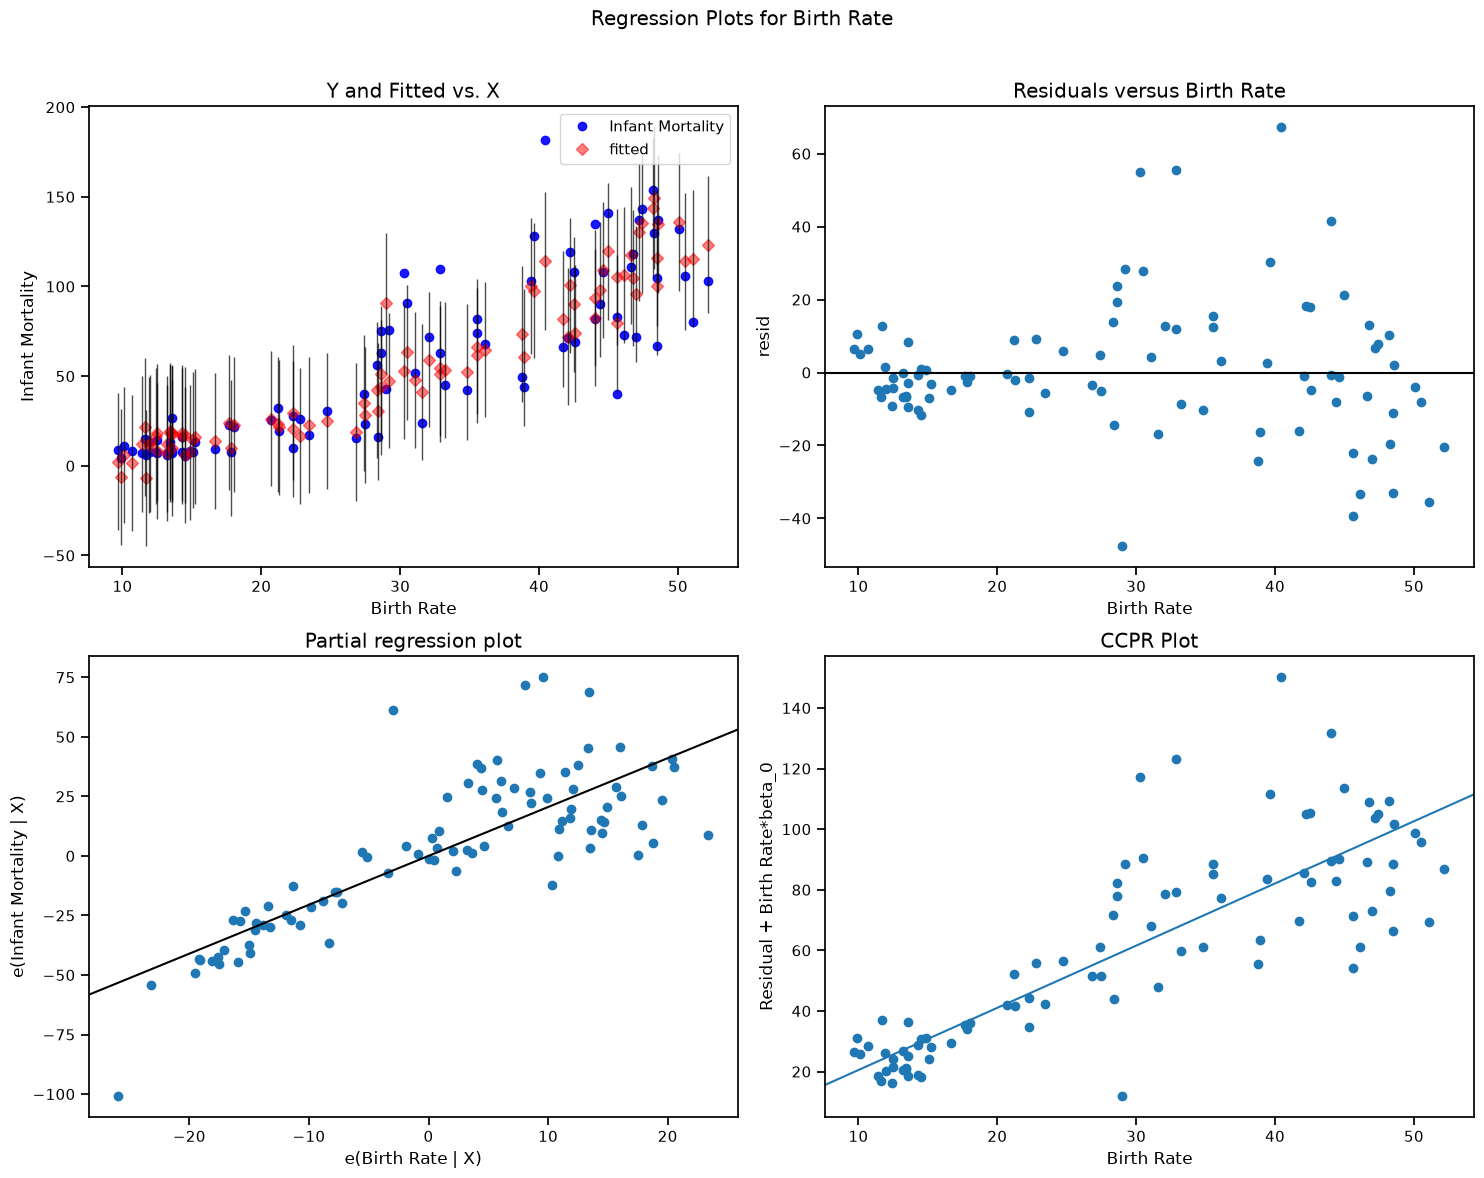

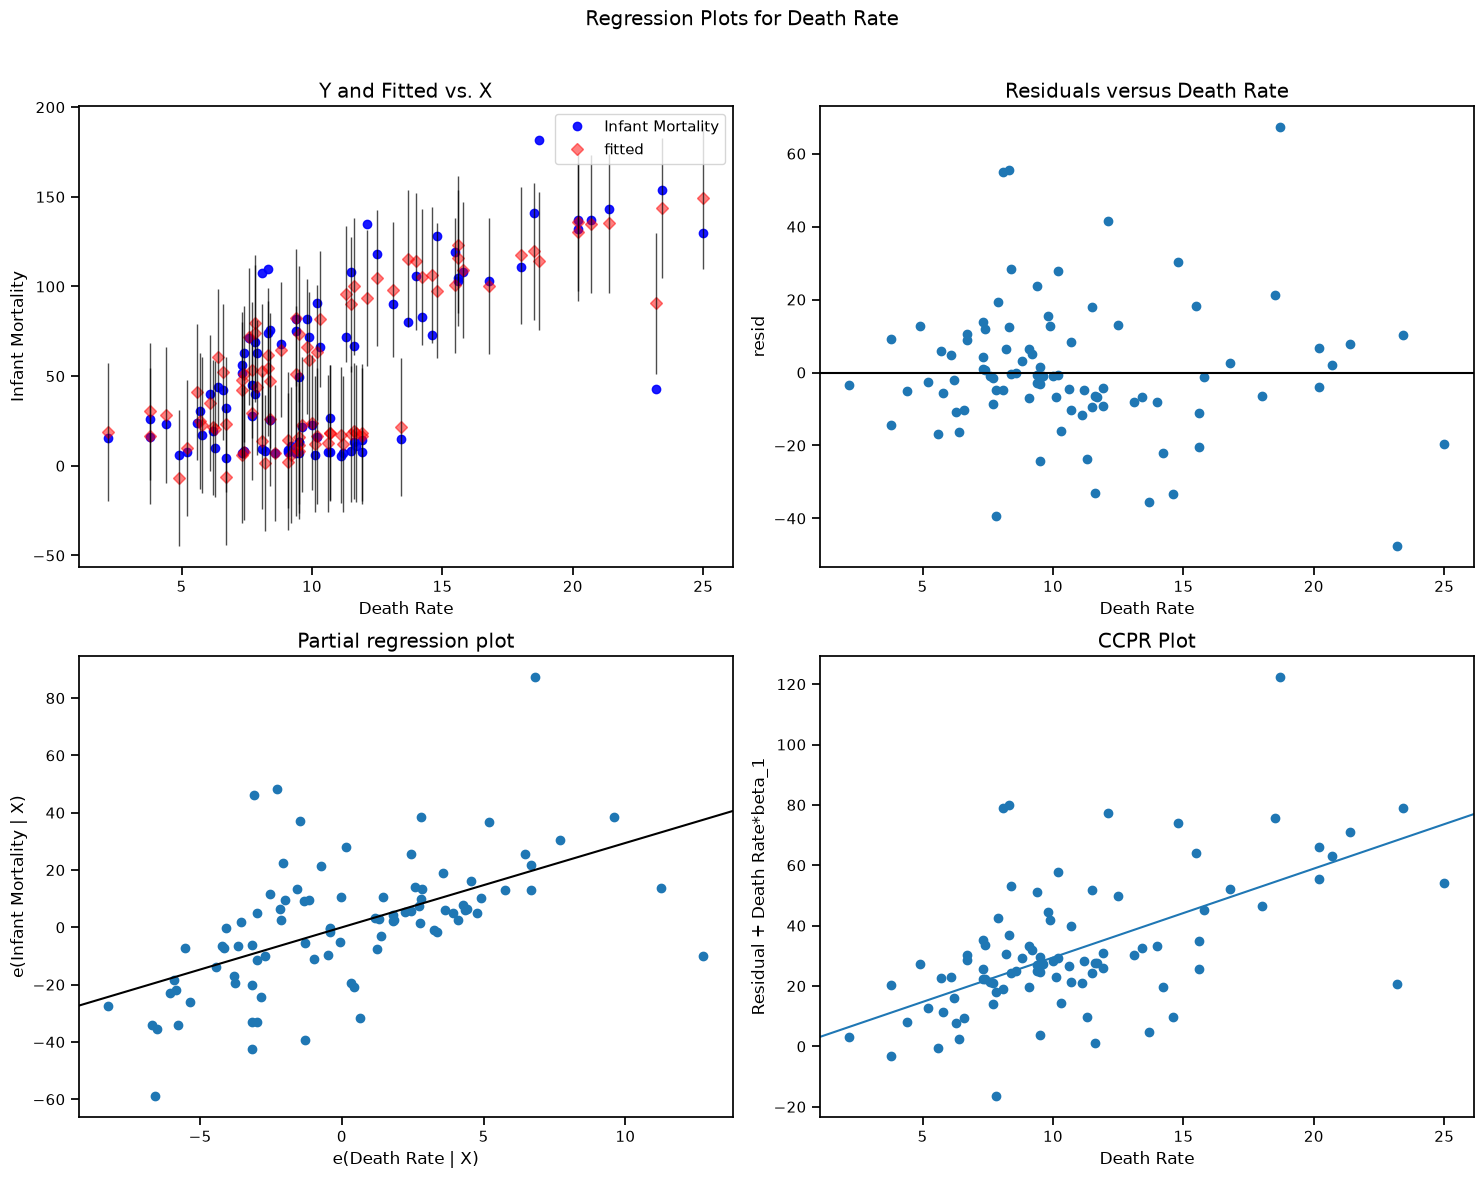

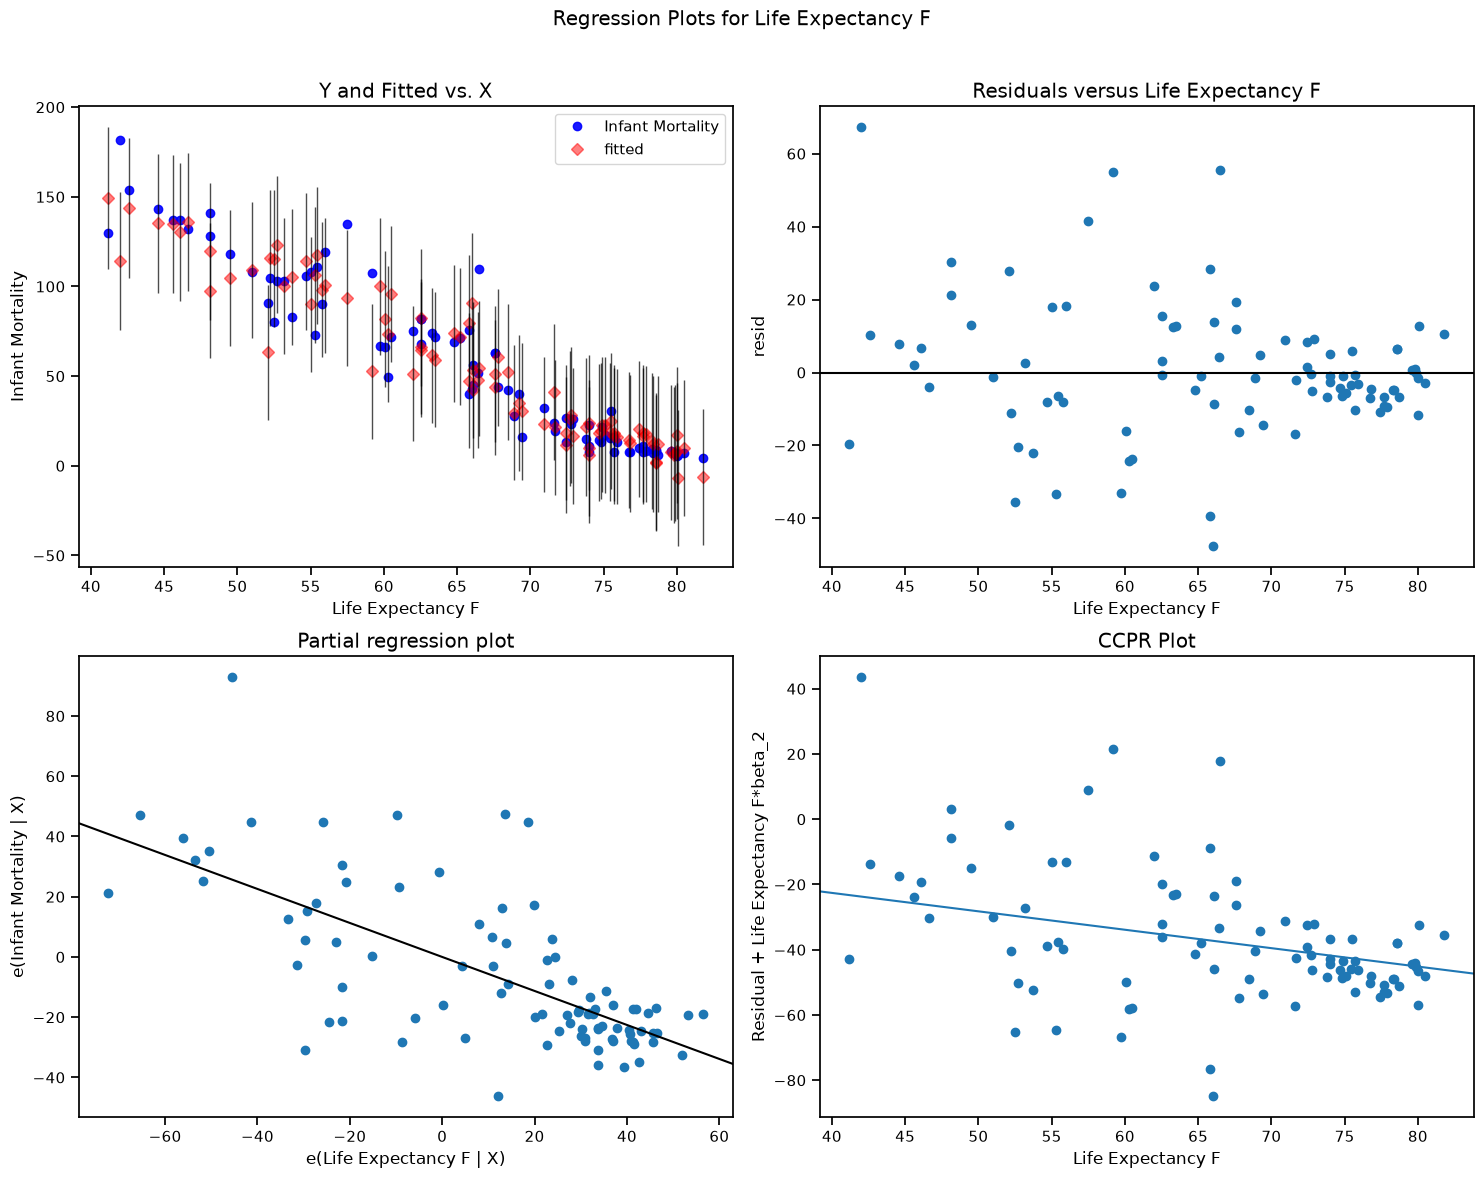

In [19]:
# put your code here
fig = plt.figure(figsize=(15, 12))
fig = sm.graphics.plot_regress_exog(reduced_results, "Birth Rate", fig=fig)
plt.show()
fig = plt.figure(figsize=(15, 12))
fig = sm.graphics.plot_regress_exog(reduced_results, "Death Rate", fig=fig)
plt.show()
fig = plt.figure(figsize=(15, 12))
fig = sm.graphics.plot_regress_exog(reduced_results, "Life Expectancy F", fig=fig)
plt.show()

**&#9989; Questions:** Based on these figures, how well does it appear your reduced model fit your data? Do you have any concerns about the distribution of the residuals?

<font size=+3>&#9998;</font> 

---
<a id="part4"></a>
## 4. Wrapping up: a look back and a look ahead

Before we finish, two short follow-ups that connect today's work to the bigger picture:

* **4.1 looks *back*** at something you ran into in Part 2 -- why the "significant" features were so unstable.
* **4.2 looks *ahead*** to what happens when the thing we want to predict isn't a number, but a **category** -- which is what we'll be exploring in subsequent classes (e.g., logistic regression in Day 15).

### 4.1 Looking back: why were the "significant" features unstable?

In Part 2 you may have noticed that the "most significant" features shifted depending on exactly which features were in the model. A common culprit is **multicollinearity** -- when two or more predictors carry nearly the *same* information, ordinary least squares can't cleanly separate their individual effects, so the coefficients and their p-values become unstable.

In fact, `statsmodels` already hinted at this. Look back at the bottom of your Part 2 `.summary()` output: there's a note warning that the **condition number** (`Cond. No.`) is large and that this "might indicate that there are strong multicollinearity or other numerical problems." That's the model itself telling you something is off -- here we'll investigate *what*.

A quick way to *see* this is a **correlation heatmap**. A second, more quantitative way (which we'll treat as an time-permitting extra) is the **Variance Inflation Factor (VIF)** -- a number computed for each predictor that measures how much that feature overlaps with (is redundant with) the *other* predictors. A VIF of 1 means no overlap; as a rough rule of thumb, a VIF above about **5-10** signals problematic multicollinearity. (The name reflects that collinearity *inflates the variance* -- i.e. the uncertainty -- of the estimated coefficient. If this is your first time seeing VIF, that's fine -- treat this as a first introduction.)

**&#9989; Do This:** Two things:

1. Make a **correlation heatmap** of the numeric columns (`Birth Rate`, `Death Rate`, `Infant Mortality`, `Life Expectancy M`, `Life Expectancy F`, `GNP`, `Group`) so you can see which features move together. (`seaborn`'s `heatmap` applied to a DataFrame's `.corr()` is an easy way to do this.)

2. **(time permitting):** Compute the **VIF** for each of your **predictor** features (i.e. not the target, `Infant Mortality`). `statsmodels` provides this (see the [`variance_inflation_factor` documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html)): `from statsmodels.stats.outliers_influence import variance_inflation_factor`. It takes your feature matrix as a NumPy array plus the column index of the feature, i.e. `variance_inflation_factor(X.values, i)`. Build the feature matrix the same way you did for your OLS models (remember what `sm.add_constant` does), then print the VIF for each feature. *Don't worry if you run out of time for this one -- the heatmap alone is enough to answer the question below; the VIF is a nice quantitative bonus if time allows.*

In [ ]:
# put your code here


**&#9989; Question:** What does the heatmap (and the VIFs, if you computed them) reveal about the features? How does that help explain why the "significant" features in Part 2 were unstable, and what is **one** thing you could do about it?

<font size=+3>&#9998;</font> Do this - Erase this and put your answer here.

### 4.2 Looking ahead: what if we're predicting a *category*?

Regression is a whole **family** of techniques, and everything we've done so far has predicted a **number**
(infant mortality). But very often the thing we care about is a **category** -- will a loan default (yes/no),
is a tumor malignant (yes/no), which species is this? What happens if we try to force our familiar
linear-regression tool onto a categorical target?

Let's find out, using the data we already have. We'll turn `Infant Mortality` into a **binary category** --
`1` ("high") if it's above the median, `0` ("low") otherwise.

To keep the focus on the regression (not on data wrangling), the target is made for you in the cell below.
**Run it as-is.** It compares each country's infant mortality to the median -- which gives `True`/`False` --
and then `.astype(int)` turns those into `1`/`0`. The result is stored in **`y_class`**, and that is the
value you'll try to model.

In [ ]:
# Run this cell as-is -- it builds the binary target `y_class` from Infant Mortality.
# 1 = "high" infant mortality (above the median), 0 = "low" (at or below the median).
threshold = df["Infant Mortality"].median()
y_class = (df["Infant Mortality"] > threshold).astype(int)
y_class.head()

**&#9989; Do This:** Fit an `sm.OLS` model that predicts **`y_class`** from the other numeric features
(drop `Infant Mortality` and `Country` from the feature set), then **look at the predicted values** -- in
particular, what range do they span?

In [ ]:
# Put your code here -- fit an OLS model that predicts y_class, then inspect the predictions.


**&#9989; Question:** Why is ordinary linear regression awkward for predicting a category like this? (Think about the range of the predictions and whether they can be read as a class or a probability.) What kind of model do you think would be better suited to this task -- and when might we encounter it?

<font size=+3>&#9998;</font> Do this - Erase this and put your answer here.

**&#9989; (Optional, time permitting) Discussion:** We've now used a few members of the regression *family* -- **simple** and **multiple** linear regression here, and **polynomial** regression in the Day 14 pre-class. Others you may run into include **regularized** regression (ridge / lasso, which help tame multicollinearity like you saw in 4.1) and **logistic** regression (next class, for predicting categories). With your group, pick **one** of these and describe a situation where it would be the right tool for the job.

<font size=+3>&#9998;</font> Do this - Erase this and put your answer here.

-----
### Congratulations, you're done with your in-class assignment!

Now, you just need to submit this assignment by uploading it to the course <a href="https://d2l.msu.edu/">Desire2Learn</a> web page for today's submission folder (Don't forget to add your names in the first cell).

&#169; Copyright 2026,  Department of Computational Mathematics, Science and Engineering at Michigan State University

<!-- Updated for FS26 (10/2026) -->